# Bonus : repérer une injection SQL dans les paramètres d'une requête HTTP

Projet final IA Cyber (APSI-NE, Programme Excellence), sujet B : étude de cas MOVEit Transfer et CL0P.
Auteur : MOHAMED BEKA Malick

## Pourquoi ce notebook

Dans le rapport, les phases 3 et 4 de la kill chain (livraison et exploitation) passent par des requêtes HTTP qui portent une injection SQL (partie 3, tableau 3). Le rapport indique que l'IA pourrait aider à les repérer, mais que des règles simples le font aussi (partie 4.3). Ce notebook teste cette idée sur un petit jeu de données public.

Ce notebook ne reproduit pas l'attaque MOVEit : il n'y a pas de trafic MOVEit ici, et rien ne dit que ces modèles auraient détecté la faille CVE-2023-34362. Il illustre seulement la détection d'un signal : « une injection SQL se trouve dans une valeur de paramètre ».

## 1. Le jeu de données

Le jeu utilisé est **HttpParamsDataset** (dépôt GitHub de Morzeux, https://github.com/Morzeux/HttpParamsDataset). D'après son README, chaque ligne est une valeur de paramètre de requête HTTP. Les valeurs normales (19 304) viennent des requêtes bénignes du jeu CSIC 2010. Les injections SQL (10 852) ont été générées avec l'outil sqlmap. Le jeu contient aussi quelques XSS, injections de commandes et traversées de chemin, qui sont laissées de côté parce qu'elles ne sont pas le signal étudié.

Deux limites à garder en tête dès le départ. Les attaques sont **générées par un outil**, donc elles se ressemblent beaucoup entre elles. Et les valeurs normales viennent d'un site de démonstration (des noms, adresses et identifiants), pas d'un serveur de transfert de fichiers.

In [1]:
import re, math, random, sys, os, urllib.request
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import IsolationForest
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score

print("python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__)

SEED = 42
DATA_URL = "https://raw.githubusercontent.com/Morzeux/HttpParamsDataset/master/payload_full.csv"
LOCAL = os.path.join("data", "payload_full.csv")
if not os.path.exists(LOCAL):
    os.makedirs("data", exist_ok=True)
    req = urllib.request.Request(DATA_URL, headers={"User-Agent": "Mozilla/5.0"})
    open(LOCAL, "wb").write(urllib.request.urlopen(req, timeout=60).read())
df = pd.read_csv(LOCAL)
print(df.shape, df.columns.tolist())
df["attack_type"].value_counts()

python 3.14.3 | pandas 3.1.0 | numpy 2.5.4 | scikit-learn 1.9.1


(31067, 4) ['payload', 'length', 'attack_type', 'label']


attack_type
norm              19304
sqli              10852
xss                 532
path-traversal      290
cmdi                 89
Name: count, dtype: int64

**Lecture.** Le fichier contient 31 067 valeurs et quatre colonnes. Les valeurs normales sont les plus nombreuses (19 304), suivies des injections SQL (10 852). Les trois autres types d'attaque sont rares (532, 290 et 89), ce qui confirme qu'on peut les laisser de côté pour cette étude.

## 2. Exploration

On regarde la répartition des classes, la longueur des valeurs et quelques exemples, et on vérifie qu'il n'y a ni doublons ni valeurs manquantes, parce que des doublons entre l'entraînement et le test fausseraient l'évaluation.

valeurs manquantes : 0 | doublons : 0
{'normal': 0.64, 'sqli': 0.36}

               count  mean   50%    max
attack_type                            
norm         19304.0  11.8   9.0   64.0
sqli         10852.0  90.5  75.0  280.0

norm -> ['castellcir', 'c/ la paloma, 32 12-a', 'satandera', 'cherwin4@xavipetit.mu', '84314573t']
sqli -> ["1') where 4092=4092 or char(75)||char(70)||char(99)||char(83)=regexp_substring(r", "1'||(select 'dfmw' from dual where 1723=1723;select (case when (4769=4769) then ", '1%"))) and 3824=benchmark(5000000,md5(0x76555642)) and ((("%"="', "1' where 6953=6953 or 2367=(select count(*) from rdb$fields as t1,rdb$types as t", "-6233') where 9820=9820 or 3038=3038"]


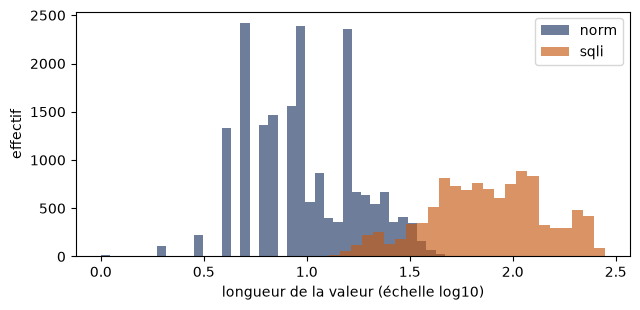

In [2]:
d = df[df.attack_type.isin(["norm", "sqli"])].copy()
d["y"] = (d.attack_type == "sqli").astype(int)
print("valeurs manquantes :", int(d.isna().sum().sum()), "| doublons :", int(d.payload.duplicated().sum()))
print(d.y.value_counts(normalize=True).rename({0: "normal", 1: "sqli"}).round(3).to_dict())
print()
print(d.groupby("attack_type")["length"].describe().round(1)[["count", "mean", "50%", "max"]])
print()
for t in ["norm", "sqli"]:
    print(t, "->", d[d.attack_type == t].payload.sample(5, random_state=1).str[:80].tolist())

fig, ax = plt.subplots(figsize=(6.5, 3.2))
for t, c in [("norm", "#1F3864"), ("sqli", "#C55A11")]:
    ax.hist(np.log10(d[d.attack_type == t].length.clip(lower=1)), bins=40, alpha=0.65, label=t, color=c)
ax.set_xlabel("longueur de la valeur (échelle log10)"); ax.set_ylabel("effectif"); ax.legend(); plt.tight_layout(); plt.show()

**Lecture.** Il n'y a ni valeur manquante ni doublon. Après filtrage, le jeu compte 64 % de valeurs normales et 36 % d'injections. Cette part de 36 % n'est pas réaliste : sur un vrai serveur, les requêtes malveillantes sont une petite minorité, donc les scores mesurés ici seront plus flatteurs que dans la réalité.

La longueur montre déjà une grande différence. Une valeur normale fait 11,8 caractères en moyenne (9 de médiane, 64 au maximum) et une injection 90,5 (75 de médiane, 280 au maximum). Les deux histogrammes se chevauchent à peine, ce qui rend le problème plutôt facile.

## 3. Préparation et séparation entraînement / test

Les données sont séparées **avant** toute transformation ou tout entraînement, avec une répartition stratifiée (75 % entraînement, 25 % test) et une graine fixe. Les modèles n'apprennent donc que sur l'entraînement et le test reste inconnu pour eux. Aucun doublon n'existe entre les deux ensembles puisqu'il n'y en a pas dans les données.

In [3]:
Xtr, Xte, ytr, yte = train_test_split(d["payload"], d["y"], test_size=0.25, stratify=d["y"], random_state=SEED)
print("entraînement :", len(Xtr), "| part de sqli :", round(ytr.mean(), 3))
print("test         :", len(Xte), "| part de sqli :", round(yte.mean(), 3))

entraînement : 22617 | part de sqli : 0.36
test         : 7539 | part de sqli : 0.36


**Lecture.** Les deux ensembles gardent la même proportion de 36 % d'injections, donc les résultats sont comparables. Les classes ne sont pas rééquilibrées : le déséquilibre est modéré, et le modèle supervisé utilise `class_weight="balanced"`.

## 4. Trois approches, du plus simple au plus fin

1. **Des règles simples**, comme celles qu'un analyste écrirait à la main : mots-clés SQL, marqueurs de commentaire, motif « ou 1=1 ». C'est la base que le cours recommande de tester d'abord.
2. **Un modèle supervisé** : régression logistique sur des n-grammes de caractères (TF-IDF). Il apprend à partir d'exemples étiquetés d'injections.
3. **Une détection d'anomalies** : Isolation Forest entraînée **seulement sur des valeurs normales**, avec quelques variables simples (longueur, part de chiffres, part de caractères spéciaux, nombre de guillemets et de parenthèses, entropie). Le seuil est fixé pour que 1 % des valeurs normales de l'entraînement soient signalées. Ce modèle n'a jamais vu d'attaque, comme dans le cas d'un zero-day.

In [4]:
RULES = [r"\b(select|union|insert|update|delete|drop|sleep|benchmark|waitfor|exec)\b",
         r"(--|/\*|#)",
         r"\b(or|and)\b\s*['\"(]?\s*\w+\s*['\"]?\s*=\s*['\"]?\w+"]
rx = [re.compile(p, re.I) for p in RULES]
def rules_pred(s):
    return np.array([int(any(r.search(v) for r in rx)) for v in s])

# modèle supervisé
vec = TfidfVectorizer(analyzer="char", ngram_range=(2, 4), min_df=3, sublinear_tf=True, lowercase=True)
Ttr = vec.fit_transform(Xtr); Tte = vec.transform(Xte)
lr = LogisticRegression(max_iter=2000, class_weight="balanced", C=3.0).fit(Ttr, ytr)
p_lr = lr.predict_proba(Tte)[:, 1]

# détection d'anomalies
def feats(s):
    out = []
    for v in s:
        n = max(len(v), 1); cnt = {}
        for ch in v: cnt[ch] = cnt.get(ch, 0) + 1
        ent = -sum(k / n * math.log2(k / n) for k in cnt.values())
        out.append([len(v), sum(ch.isdigit() for ch in v) / n, sum(ch.isalpha() for ch in v) / n,
                    sum((not ch.isalnum()) and ch != " " for ch in v) / n,
                    v.count("'") + v.count('"'), v.count("(") + v.count(")"), v.count(" "), ent])
    return np.array(out)
Ftr, Fte = feats(Xtr), feats(Xte)
iso = IsolationForest(n_estimators=300, random_state=SEED).fit(Ftr[ytr.values == 0])
s_tr = -iso.score_samples(Ftr[ytr.values == 0]); s_te = -iso.score_samples(Fte)
thr = np.quantile(s_tr, 0.99)
pred = {"règles": rules_pred(Xte), "régression logistique": (p_lr > 0.5).astype(int), "Isolation Forest": (s_te > thr).astype(int)}
print("seuil d'anomalie (99e centile du normal) :", round(float(thr), 4))
print({k: int(v.sum()) for k, v in pred.items()}, "alertes sur", len(Xte), "valeurs de test")

seuil d'anomalie (99e centile du normal) : 0.6292
{'règles': 2565, 'régression logistique': 2706, 'Isolation Forest': 2723} alertes sur 7539 valeurs de test


**Lecture.** Le test contient 2 713 injections. Les règles lèvent 2 565 alertes, la régression logistique 2 706 et Isolation Forest 2 723. Les deux premières sont proches du bon nombre. Isolation Forest lève plus d'alertes qu'il n'y a d'injections, ce qui annonce des faux positifs.

## 5. Évaluation

On calcule la précision, le rappel et le F1 (la classe positive est l'injection SQL), l'AUC pour les deux modèles qui donnent un score, et la matrice de confusion. Dans un SOC, un **faux négatif** (une injection non vue) coûte plus cher qu'une fausse alerte, donc le rappel est regardé en priorité. Mais les faux positifs comptent aussi à cause de la fatigue d'alertes, discutée dans la partie 5.2 du rapport.

,précision,rappel,F1,AUC,VP,FN,FP,VN,taux de FP
modèle,,,,,,,,,
règles,0.9996,0.9451,0.9716,NaN,2564,149,1,4825,0.0002
régression logistique,1.0000,0.9974,0.9987,0.9999,2706,7,0,4826,0.0000
Isolation Forest,0.9864,0.9900,0.9882,0.9997,2686,27,37,4789,0.0077


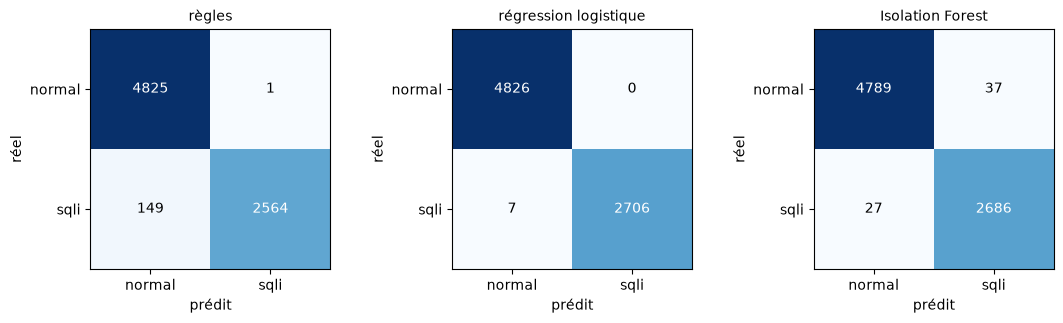

règles                 taux de FP = 0.0207% -> 21 fausses alertes pour 100 000 valeurs normales
régression logistique  taux de FP = 0.0000% -> 0 fausses alertes pour 100 000 valeurs normales
Isolation Forest       taux de FP = 0.7667% -> 767 fausses alertes pour 100 000 valeurs normales


In [5]:
scores = {"règles": None, "régression logistique": p_lr, "Isolation Forest": s_te}
rows = []
for name, p in pred.items():
    tn, fp, fn, tp = confusion_matrix(yte, p).ravel()
    rows.append({"modèle": name, "précision": precision_score(yte, p), "rappel": recall_score(yte, p), "F1": f1_score(yte, p),
                 "AUC": roc_auc_score(yte, scores[name]) if scores[name] is not None else np.nan,
                 "VP": tp, "FN": fn, "FP": fp, "VN": tn, "taux de FP": fp / (fp + tn)})
res = pd.DataFrame(rows).set_index("modèle")
display(res.round(4))

fig, axes = plt.subplots(1, 3, figsize=(11, 3.3))
for ax, (name, p) in zip(axes, pred.items()):
    cm = confusion_matrix(yte, p)
    ax.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm): ax.text(j, i, v, ha="center", va="center", color="white" if v > cm.max() / 2 else "black")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["normal", "sqli"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["normal", "sqli"])
    ax.set_xlabel("prédit"); ax.set_ylabel("réel"); ax.set_title(name, fontsize=10)
plt.tight_layout(); plt.show()

# lien avec la partie 5.2 du rapport : effet d'un taux de faux positifs sur un volume quotidien (exemple choisi, pas une mesure)
for name in res.index:
    print(f"{name:22s} taux de FP = {res.loc[name, 'taux de FP']:.4%} -> {res.loc[name, 'taux de FP'] * 100000:.0f} fausses alertes pour 100 000 valeurs normales")

**Lecture.**
- Règles : précision de 0,9996 (un seul faux positif) et rappel de 0,945, soit 149 injections manquées.
- Régression logistique : précision de 1,0, rappel de 0,997 (7 injections manquées), aucun faux positif, AUC de 0,9999.
- Isolation Forest : précision de 0,986, rappel de 0,990 (27 manquées) et 37 faux positifs, soit 0,77 % des valeurs normales.

Sans surprise, le modèle supervisé est le meilleur, puisqu'il a vu des exemples d'injections. Isolation Forest n'a jamais vu d'attaque et atteint pourtant 99 % de rappel : une détection d'anomalies peut repérer ce type d'attaque sans exemples, mais en payant avec des fausses alertes.

Le calcul sur 100 000 valeurs normales est un exemple choisi, pas une mesure : il donne 21 fausses alertes pour les règles, 0 pour la régression logistique et 767 pour Isolation Forest. C'est exactement le problème de fatigue d'alertes de la partie 5.2 du rapport. Un rappel de 99 % ne dit pas si une équipe peut traiter 767 fausses alertes par jour.

Il faut aussi rester prudent devant des scores presque parfaits. Ils viennent surtout du fait que les injections de ce jeu sont générées par un même outil et ressemblent peu aux valeurs normales. Ils ne prouvent pas que le problème est facile en vrai.

## 6. Analyse des erreurs

On regarde quelques faux négatifs (injections non vues) et faux positifs (valeurs normales signalées) de chaque modèle, pour comprendre pourquoi ils se trompent.

In [6]:
def show(title, mask, n=5):
    sub = Xte[mask]
    print(f"{title} : {int(mask.sum())}")
    for v in sub.str[:75].head(n).tolist(): print("   ", repr(v))
    print()
pr, pl, pi = pred["règles"], pred["régression logistique"], pred["Isolation Forest"]
y = yte.values
show("Règles, faux négatifs", (y == 1) & (pr == 0)); show("Règles, faux positifs", (y == 0) & (pr == 1))
show("Régression logistique, faux négatifs", (y == 1) & (pl == 0)); show("Régression logistique, faux positifs", (y == 0) & (pl == 1))
show("Isolation Forest, faux négatifs", (y == 1) & (pi == 0)); show("Isolation Forest, faux positifs", (y == 0) & (pi == 1))

Règles, faux négatifs : 149
    '-9496))) or elt(7511=3951,3951) and (((3514=3514'
    '1%"))) and make_set(8403=8403,8899) and ((("%"="'
    "1';call regexp_substring(repeat(right(char(3702),0),500000000),null)"
    "1') and make_set(7187=4625,4625) and ('diai' like 'diai"
    "1%' and make_set(1227=5627,5627) and '%'='"

Règles, faux positifs : 1
    'union, 32 8-d'

Régression logistique, faux négatifs : 7
    "'1"
    '1\'qhfy<\'">utwq'
    'elt(5953=5953,1)'
    '(8266=8266)*9900'
    'make_set(2672=2672,5440)'

Régression logistique, faux positifs : 0

Isolation Forest, faux négatifs : 27
    '1));select sleep(5)#'
    '1))) rlike sleep(5)#'
    '1 and 9122=4153# nxcv'
    '-1432 order by 1#'
    '1 and sleep(5)-- ruuv'

Isolation Forest, faux positifs : 37
    'c/ rio cea, 77,'
    'calle daniel florido rodriguez, 105, 2?f'
    'paseo marinero luis de torres, 81, 4?e'
    'castelln de la plana/castell de la plana'
    'plza. nuestra seora de los reyes 98'



**Lecture.**
- **Règles.** Les 149 injections manquées contiennent des fonctions SQL que la liste de mots-clés ne connaît pas, comme `elt`, `make_set` ou `regexp_substring`. Une règle est précise, mais elle ne voit que ce qu'on lui a écrit. Le seul faux positif est une valeur qui commence par « union » (`union, 32 8-d`) : un mot-clé peut apparaître dans une valeur normale.
- **Régression logistique.** Les 7 injections manquées sont très courtes (`'1`, `elt(5953=5953,1)`, `(8266=8266)*9900`), donc elles offrent peu de motifs de caractères au modèle. Aucun faux positif.
- **Isolation Forest.** Les 27 injections manquées sont courtes, avec un `sleep` ou un `order by` suivi d'un commentaire, et elles ressemblent à des valeurs normales pour les huit variables simples du modèle. Les règles auraient attrapé les cinq exemples affichés (mots `sleep` ou `select`, ou marqueur `#` ou `--`). Les 37 faux positifs sont des adresses espagnoles aux caractères abîmés (`2?f`, `castelln`) ou pleines de virgules : elles sortent de ce que le modèle a appris. Cela rappelle le biais vu en cours, où un modèle juge anormal ce qui ne ressemble pas à ses données d'entraînement.

Les erreurs ne se recouvrent pas, donc combiner règles et modèle compléterait chacun.

## 7. Un test d'évasion simple

Le cours explique qu'un attaquant peut modifier son entrée pour tromper un détecteur sans changer l'effet de l'attaque (attaque par évasion). Trois transformations très simples sont testées sur les injections du jeu de test : casse aléatoire, remplacement des espaces par des commentaires `/**/`, et encodage URL des caractères `' " ( ) = ;`. Ce n'est pas une vraie attaque adversariale (l'attaquant ne regarde pas les scores du modèle), seulement un premier test de solidité. Le rappel de chaque modèle est mesuré sur les injections transformées.

,sans modification,casse aléatoire,espaces vers /**/,encodage URL
règles,0.945,0.945,0.992,0.622
régression logistique,0.997,0.997,0.898,0.976
Isolation Forest,0.990,0.990,0.999,0.988


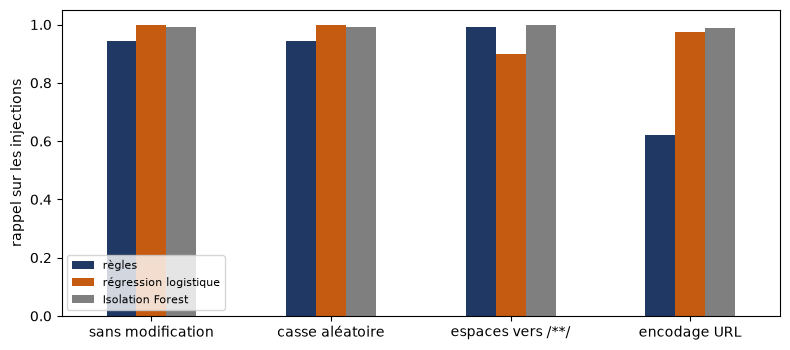

In [7]:
random.seed(7)
def rcase(v): return "".join(ch.upper() if random.random() < 0.5 else ch.lower() for ch in v)
def comments(v): return v.replace(" ", "/**/")
def urlenc(v): return "".join(f"%{ord(ch):02X}" if ch in "'\"()=;" else ch for ch in v)
sq = Xte[yte == 1]
out = {"sans modification": [rules_pred(sq).mean(), (lr.predict_proba(vec.transform(sq))[:, 1] > 0.5).mean(), (-iso.score_samples(feats(sq)) > thr).mean()]}
for nm, f in [("casse aléatoire", rcase), ("espaces vers /**/", comments), ("encodage URL", urlenc)]:
    m = sq.map(f)
    out[nm] = [rules_pred(m).mean(), (lr.predict_proba(vec.transform(m))[:, 1] > 0.5).mean(), (-iso.score_samples(feats(m)) > thr).mean()]
ev = pd.DataFrame(out, index=["règles", "régression logistique", "Isolation Forest"])
display(ev.round(3))
ev.T.plot(kind="bar", figsize=(8, 3.6), color=["#1F3864", "#C55A11", "#7F7F7F"], ylim=(0, 1.05))
plt.ylabel("rappel sur les injections"); plt.xticks(rotation=0); plt.legend(loc="lower left", fontsize=8); plt.tight_layout(); plt.show()

**Lecture.**
- **Casse aléatoire** : aucun effet sur les trois détecteurs, puisque les règles ignorent la casse, que le modèle passe tout en minuscules et que les variables simples ne dépendent pas de la casse.
- **Espaces remplacés par `/**/`** : le rappel de la régression logistique tombe de 0,997 à 0,898, parce que ses n-grammes de caractères ne connaissent pas cette forme. Les règles montent à 0,992, puisque `/*` est l'un de leurs marqueurs, et Isolation Forest monte à 0,999.
- **Encodage URL** : les règles tombent de 0,945 à 0,622, car leur motif ne reconnaît plus les caractères encodés. La régression logistique garde 0,976 et Isolation Forest 0,988.

Chaque détecteur a donc un point faible différent, et une transformation toute simple lui fait perdre environ 10 points de rappel (régression logistique) ou 32 points (règles). C'est le principe de l'attaque par évasion vue en cours. Ici, l'attaquant n'a même pas regardé les scores du modèle. La parade présentée en cours (l'entraînement adversarial) consisterait à ajouter ces variantes aux données d'entraînement. Elle n'a pas été testée.

## 8. Conclusion et limites

**À retenir.**
1. Des règles simples font déjà un bon travail : 94,5 % de rappel et un seul faux positif. Elles sont lisibles et faciles à corriger, ce qui rejoint la grille du cours (règles d'abord, IA en soutien).
2. Le modèle supervisé est le meilleur sur ces données (99,7 % de rappel, aucun faux positif), mais ce résultat est flatteur, parce que les injections sont générées par un outil et très différentes des valeurs normales.
3. La détection d'anomalies trouve 99 % des injections sans en avoir jamais vu, mais lève environ 767 fausses alertes pour 100 000 valeurs normales. C'est la limite décrite à la partie 5.2 du rapport.
4. Chaque approche a un point faible face à des variantes simples, donc combiner règles et modèle est plus solide qu'un seul détecteur.

**Limites.**
- Les injections sont générées par sqlmap et les valeurs normales viennent d'un site de démonstration. Ce n'est pas du trafic MOVEit.
- Le notebook analyse seulement des valeurs de paramètres, pas les en-têtes. Il ne verrait donc pas le signal de l'en-tête `X-siLock-Comment` du web shell (partie 3).
- La part de 36 % d'attaques est irréaliste, il n'y a aucune dérive dans le temps, et un seul découpage entraînement / test a été fait, sans validation croisée ni intervalle d'incertitude.
- Les tests d'évasion sont très simples.

Ce notebook ne permet donc pas de dire que l'IA aurait détecté MOVEit. Il montre seulement qu'un signal de type « injection SQL dans une valeur de paramètre » est détectable sur un jeu public, par des règles comme par des modèles, avec des limites précises. Il faut aussi que le contenu des requêtes soit visible, par exemple derrière un pare-feu applicatif (partie 4.2 du rapport).

## Sources et usage de l'IA

- Jeu de données : Morzeux, HttpParamsDataset, https://github.com/Morzeux/HttpParamsDataset (valeurs bénignes issues de CSIC 2010, injections générées avec sqlmap, d'après son README).
- Bibliothèques : pandas, numpy, scikit-learn, matplotlib (versions affichées plus haut).
- Un assistant d'IA générative a aidé à écrire et organiser ce notebook (voir l'annexe A du rapport). Les résultats viennent de l'exécution du code ci-dessus.